In [1]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import pairwise_distances
from sklearn import metrics


In [2]:
df = pd.read_csv('../data/komdigi_hoaks.csv')
df['teks'] = df['title'].fillna('') + ' ' + df['excerpt'].fillna('')
df = df[df['teks'].str.strip() != ''].reset_index(drop=True)

print(f"Total data bersih siap klasterisasi: {len(df)} baris")
df[['title', 'teks']].head()


Total data bersih siap klasterisasi: 4176 baris


,title,teks
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,[HOAKS] Tautan Pencairan BSU September 2026 Se...
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...


In [3]:
tfidf = TfidfVectorizer(max_features=1000)
X = tfidf.fit_transform(df['teks']).toarray()

print("Bentuk matriks TF-IDF:", X.shape)


Bentuk matriks TF-IDF: (4176, 1000)


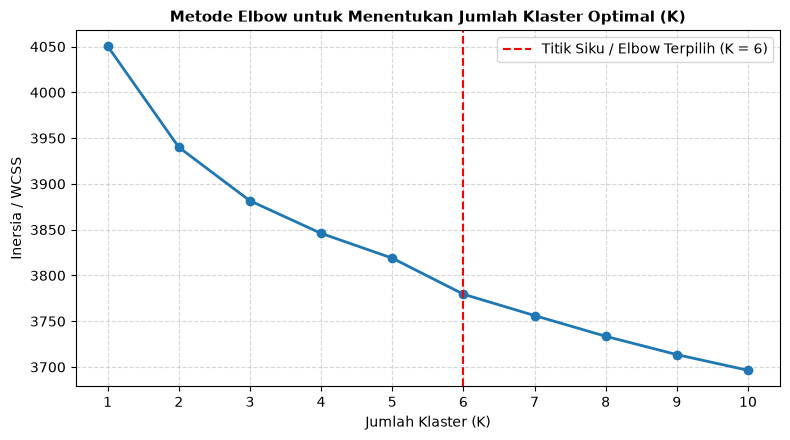

In [4]:
# Penentuan Jumlah Klaster Optimal dengan Metode Elbow
from sklearn.cluster import KMeans

wcss = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=5)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4.5))
plt.plot(K, wcss, marker='o', color='#1f77b4', linewidth=2, markersize=6)
plt.title('Metode Elbow untuk Menentukan Jumlah Klaster Optimal (K)', fontsize=11, fontweight='bold')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Inersia / WCSS')
plt.xticks(list(K))
plt.axvline(x=6, color='red', linestyle='--', label='Titik Siku / Elbow Terpilih (K = 6)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [5]:
# Algoritma Divisive Hierarchical Clustering (Top-Down Bisection)
class DivisiveHierarchicalClustering:
    def __init__(self, n_clusters=6, metric='euclidean', random_state=42):
        self.n_clusters = n_clusters
        self.metric = metric
        self.random_state = random_state

    def fit_predict(self, X):
        np.random.seed(self.random_state)
        clusters = [np.arange(X.shape[0])]

        while len(clusters) < self.n_clusters:
            # Ambil klaster terbesar untuk dipecah (top-down)
            split_idx = int(np.argmax([len(c) for c in clusters]))
            current_cluster = clusters.pop(split_idx)
            sub_X = X[current_cluster]

            # Inisialisasi 2 benih pusat terjauh
            seed1 = np.random.randint(len(current_cluster))
            dists1 = pairwise_distances(sub_X[seed1:seed1+1], sub_X, metric=self.metric).flatten()
            seed2 = int(np.argmax(dists1))

            c1, c2 = sub_X[seed1:seed1+1], sub_X[seed2:seed2+1]

            for _ in range(5):
                d1 = pairwise_distances(sub_X, c1, metric=self.metric).flatten()
                d2 = pairwise_distances(sub_X, c2, metric=self.metric).flatten()
                assign = d1 > d2
                if np.all(assign) or not np.any(assign):
                    break
                if self.metric == 'manhattan':
                    c1 = np.median(sub_X[~assign], axis=0, keepdims=True)
                    c2 = np.median(sub_X[assign], axis=0, keepdims=True)
                else:
                    c1 = np.mean(sub_X[~assign], axis=0, keepdims=True)
                    c2 = np.mean(sub_X[assign], axis=0, keepdims=True)

            d1 = pairwise_distances(sub_X, c1, metric=self.metric).flatten()
            d2 = pairwise_distances(sub_X, c2, metric=self.metric).flatten()
            assign = d1 > d2

            clusters.append(current_cluster[~assign])
            clusters.append(current_cluster[assign])

        labels = np.zeros(X.shape[0], dtype=int)
        for i, c in enumerate(clusters):
            labels[c] = i
        return labels

print("Model Divisive Hierarchical Clustering siap dieksekusi.")


Model Divisive Hierarchical Clustering siap dieksekusi.


In [6]:
# Mulai pelacakan memori & waktu
tracemalloc.start()
waktu_mulai = time.time()

model = DivisiveHierarchicalClustering(n_clusters=6, metric='euclidean')
df['cluster_divisive_euclidean'] = model.fit_predict(X)

waktu_selesai = time.time()
mem_sekarang, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

labels = df['cluster_divisive_euclidean']
hasil_jumlah_klaster = len(set(labels))
jumlah_noise = 0
hasil_waktu = waktu_selesai - waktu_mulai
hasil_memori_mb = mem_puncak / (1024 * 1024)
hasil_silhouette = metrics.silhouette_score(X, labels, metric='euclidean')
hasil_dbi = metrics.davies_bouldin_score(X, labels)

print("=" * 45)
print("HASIL PENGUJIAN: HIERARCHICAL DIVISIVE EUCLIDEAN")
print("=" * 45)
print(f"1. Jumlah Klaster   : {hasil_jumlah_klaster} klaster (dan {jumlah_noise} data noise)")
print(f"2. Waktu Eksekusi    : {hasil_waktu:.4f} detik")
print(f"3. Silhouette Score : {hasil_silhouette:.4f} (metrik euclidean)")
print(f"4. Penggunaan Memori: {hasil_memori_mb:.2f} MB")
print(f"5. Davies-Bouldin   : {hasil_dbi:.4f} (semakin mendekati 0 semakin baik)")
print("=" * 45)


HASIL PENGUJIAN: HIERARCHICAL DIVISIVE EUCLIDEAN
1. Jumlah Klaster   : 6 klaster (dan 0 data noise)
2. Waktu Eksekusi    : 0.6810 detik
3. Silhouette Score : 0.0233 (metrik euclidean)
4. Penggunaan Memori: 58.11 MB
5. Davies-Bouldin   : 7.3468 (semakin mendekati 0 semakin baik)


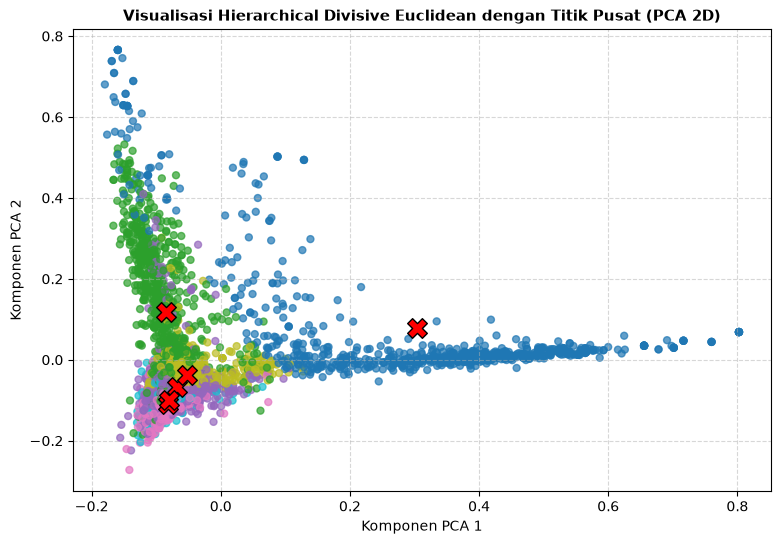

In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]

plt.figure(figsize=(9, 6))
plt.scatter(
    df['pca1'],
    df['pca2'],
    c=df['cluster_divisive_euclidean'],
    cmap='tab10',
    s=25,
    alpha=0.7,
    label='Klaster'
)

for c in sorted(df['cluster_divisive_euclidean'].unique()):
    pusat_x = df[df['cluster_divisive_euclidean'] == c]['pca1'].mean()
    pusat_y = df[df['cluster_divisive_euclidean'] == c]['pca2'].mean()
    plt.scatter(pusat_x, pusat_y, marker='X', s=200, color='red', edgecolors='black')

plt.title('Visualisasi Hierarchical Divisive Euclidean dengan Titik Pusat (PCA 2D)', fontsize=11, fontweight='bold')
plt.xlabel('Komponen PCA 1')
plt.ylabel('Komponen PCA 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [8]:
terms = tfidf.get_feature_names_out()
unique_clusters = sorted(df['cluster_divisive_euclidean'].unique())

print("Kata Kunci Dominan Tiap Klaster Hierarchical Divisive Euclidean:")
for c in unique_clusters:
    idx = df[df['cluster_divisive_euclidean'] == c].index
    mean_tfidf = np.asarray(X[idx].mean(axis=0)).flatten()
    top_terms = [terms[i] for i in mean_tfidf.argsort()[::-1][:7]]
    print(f"[Klaster {c}] ({len(idx)} data): {', '.join(top_terms)}")


Kata Kunci Dominan Tiap Klaster Hierarchical Divisive Euclidean:
[Klaster 0] (775 data): mengatasnamakan, akun, whatsapp, hoaks, kabupaten, bupati, facebook
[Klaster 1] (855 data): tautan, pendaftaran, hoaks, bantuan, untuk, 2026, dari
[Klaster 2] (694 data): di, hoaks, video, pada, yang, indonesia, dan
[Klaster 3] (341 data): presiden, prabowo, jokowi, hoaks, ijazah, gibran, tidak
[Klaster 4] (1192 data): hoaks, indonesia, dan, yang, tidak, dari, pada
[Klaster 5] (319 data): video, ai, hoaks, artificial, hasil, intelligence, persen
